# Controlled simulation: Supplementary Fig. 10

Three saved simulation seeds (123, 124, 125) link the observed modalities, target labels, embeddings and final probe evaluations. This experiment evaluates target prediction, not tissue clustering.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/06_Controlled_simulation/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "06_Controlled_simulation"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Display the saved targets

`meta.csv` contains region R, modality-specific U and C, and the joint target Y. The 44 × 44 spatial grid shown here is the existing seed-123 dataset.

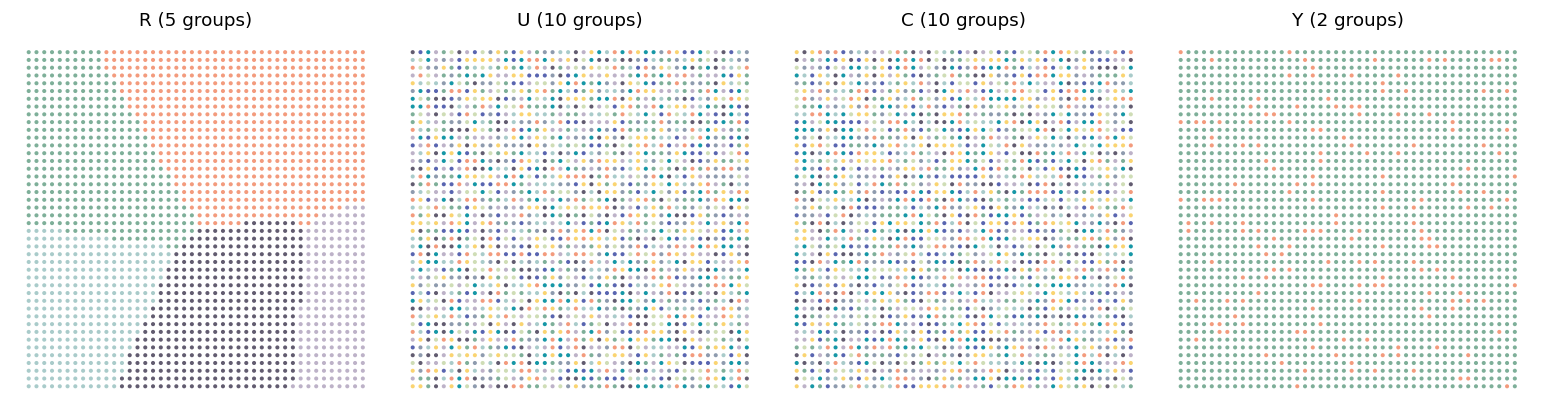

In [2]:
meta = pd.read_csv(DATA / "01_source_data/seed123/meta.csv")
assert len(meta) == 44 * 44
show(spatial_panels(meta, ["R", "U", "C", "Y"], ncols=4, point_size=6))

## 2. Trace the saved log-transformed inputs to the embedding

`02_model_inputs` contains the already prepared inputs. This cell reads their dimensions and the existing embedding only.

In [3]:
rows = []
for seed in [123, 124, 125]:
    rna = np.load(DATA / f"02_model_inputs/seed{seed}/X_rna.npy", mmap_mode="r")
    atac = np.load(DATA / f"02_model_inputs/seed{seed}/X_atac.npy", mmap_mode="r")
    embedding = read_indexed(DATA / f"03_embeddings/seed{seed}/MELON.csv")
    rows.append({"seed": seed, "RNA": str(rna.shape), "ATAC": str(atac.shape), "MELON": str(embedding.shape)})
display(pd.DataFrame(rows))

,seed,RNA,ATAC,MELON
0,123,"(1936, 600)","(1936, 600)","(1936, 256)"
1,124,"(1936, 600)","(1936, 600)","(1936, 256)"
2,125,"(1936, 600)","(1936, 600)","(1936, 256)"


## 3. Plot the already evaluated probes

The saved headline evaluation uses an MLP for Y and a linear SVM for R/U/C. Bars and error bars read the stored three-seed mean and standard deviation. No classifier is fitted here.

For Seurat, select the saved WNN representation; its separate UMAP-only evaluation is not the headline input.

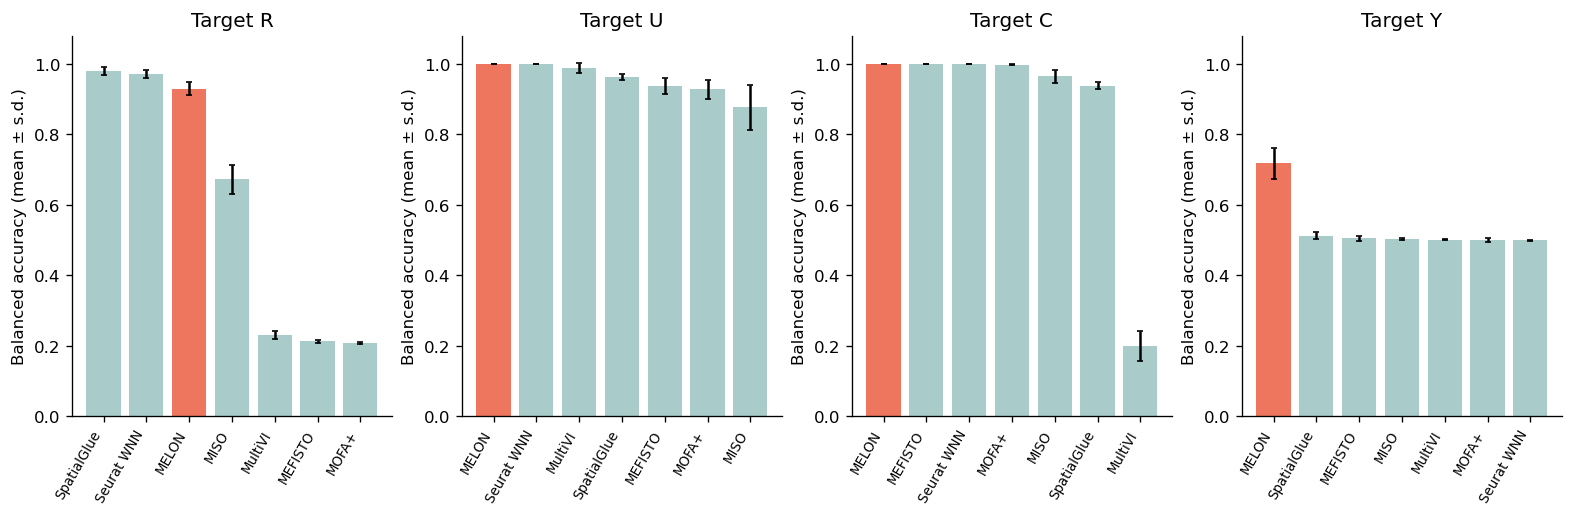

In [4]:
EVALUATION = DATA / "04_saved_evaluation"
melon = pd.read_csv(EVALUATION / "MELON_summary.csv")
baselines = pd.read_csv(EVALUATION / "external_headline_y_mlp_ruc_linsvm_summary.csv")
baselines = baselines.loc[(baselines.method != "seurat") |
                          (baselines.embedding == "latent_seurat_wnn.csv")]
scores = simulation_scores(melon, baselines)
show(simulation_score_panels(scores))

## 4. Inspect the existing ablation results

Select the same saved MLP probe used for Y; do not mix it with the linear-SVM rows.

In [5]:
ablation = pd.read_csv(EVALUATION / "a1scale1_same_probe_y_melon_ablation_summary.csv")
display(ablation.loc[ablation.probe == "mlp", ["method", "n_seeds", "balanced_accuracy_mean", "balanced_accuracy_std"]]
        .sort_values("balanced_accuracy_mean", ascending=False).reset_index(drop=True))

,method,n_seeds,balanced_accuracy_mean,balanced_accuracy_std
0,MELON full+aug,3,0.718434,0.043915
1,MELON no-space+aug,3,0.592008,0.032978
2,MELON full no-aug,3,0.515853,0.017582
3,MELON no-space no-aug,3,0.508733,0.007548
4,MELON RNA-only+aug,3,0.500000,0.000000
5,MELON ATAC-only+aug,3,0.499814,0.000663


The archive includes the original per-seed evaluation CSV files alongside these summaries. The source directory named `totalvi` corresponds to **MultiVI** in this simulation; the display name above follows the archived README. No new cluster labels are introduced.